# TaskFlow: Task Management REST API using FastAPI and MySQL
**ITW III Course Project**

**What this project does:** a web API (running on localhost) that lets users register, log in, and manage their own tasks (create, read, update, delete). Data is stored in a **MySQL** database. The notebook also seeds the database with fake data, tests every endpoint, and draws analytics charts.

**Base project:** [isaac0yen/Python-CRUD](https://github.com/isaac0yen/Python-CRUD) (FastAPI + SQLAlchemy + SQLite task manager).

### What came from the base project vs. what I added
| Part | From base project | Added / modified by me |
|---|---|---|
| FastAPI app + task CRUD routes | Yes (idea and structure: models / routes / database setup) | Rewritten, with validation and ownership checks |
| Database | SQLite | **Changed to MySQL** (PyMySQL driver) |
| Tables | One `Task` table | **Second table `User`**, linked by a foreign key, plus indexes |
| Login | None | **JWT login + bcrypt password hashing** |
| Filtering | Due date, completion | **Status, priority, category, due date, title search, pagination** |
| Analytics | None | **3 analytics endpoints + Pandas/Matplotlib charts** |
| Data | Manual entry | **Faker-generated seed data (about 1000 tasks)** |
| Testing | None | **Automated tests of all endpoints from the notebook** |

### Contents
1. Setup and imports  
2. Database connection (MySQL)  
3. Tables (models)  
4. Data shapes (Pydantic schemas)  
5. Security (password hashing and JWT)  
6. The FastAPI application (endpoints)  
7. Seed the database with data  
8. Start the server  
9. Test the API  
10. Analytics and charts  
11. Conclusion

## 1. Setup and imports

**Libraries used (in simple words)**
- **FastAPI**: turns Python functions into web addresses (endpoints) such as `/tasks`.
- **Uvicorn**: the small web server that runs the FastAPI app on your computer.
- **SQLAlchemy**: lets us use database tables as Python classes (an *ORM*), so we write very little SQL.
- **PyMySQL**: the driver that lets Python talk to MySQL.
- **Pydantic**: checks that incoming data is valid (for example, priority must be Low, Medium or High).
- **python-jose and passlib (bcrypt)**: login tokens (JWT) and safe password storage.
- **Faker**: creates realistic fake names, emails and sentences.
- **Requests**: sends HTTP calls to our API (used for testing).
- **Pandas and Matplotlib**: tables and charts for the analytics.

Install once (remove the `#` to run):

In [1]:
%pip install fastapi uvicorn sqlalchemy pymysql cryptography "python-jose" "passlib[bcrypt]" "bcrypt==4.0.1" faker pandas matplotlib requests pydantic email-validator python-multipart

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, random, threading
from datetime import date, datetime, timedelta, timezone
from typing import Optional, Literal, List

import requests
import uvicorn
import pandas as pd
import matplotlib.pyplot as plt
from faker import Faker

from fastapi import FastAPI, Depends, HTTPException, Query
from fastapi.security import OAuth2PasswordBearer, OAuth2PasswordRequestForm
from pydantic import BaseModel, EmailStr, Field, ConfigDict

from sqlalchemy import (create_engine, Column, Integer, String, Text, Date,
                        DateTime, ForeignKey, func, case)
from sqlalchemy.orm import declarative_base, sessionmaker, relationship, Session

from jose import jwt, JWTError
from passlib.context import CryptContext

print("All libraries imported successfully")

All libraries imported successfully


## 2. Database connection (MySQL)

**Step 1 (do once, in the MySQL command line or Workbench):**
```sql
CREATE DATABASE taskflow_db;
```
**Step 2:** put your own MySQL username and password below. The values are read from environment variables if they exist, so the password does not have to be written in the code.

**Key terms**
- **Engine**: the connection to the database.
- **Session**: one "conversation" with the database (query, add, commit).
- **Base**: the parent class for all our table classes.
- **`get_db()`**: gives each API request its own session, and closes it afterwards.

In [3]:
DB_USER     = os.getenv("TASKFLOW_DB_USER", "root")
DB_PASSWORD = os.getenv("TASKFLOW_DB_PASSWORD", "your_mysql_password")   # <-- change this (if it contains @, type %40 instead)
DB_HOST     = os.getenv("TASKFLOW_DB_HOST", "localhost")
DB_PORT     = os.getenv("TASKFLOW_DB_PORT", "3306")
DB_NAME     = os.getenv("TASKFLOW_DB_NAME", "taskflow_db")

DATABASE_URL = f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"

engine = create_engine(DATABASE_URL, pool_pre_ping=True)
SessionLocal = sessionmaker(bind=engine, autoflush=False, autocommit=False)
Base = declarative_base()

def get_db():
    db = SessionLocal()
    try:
        yield db
    finally:
        db.close()

# quick connection check
with engine.connect() as conn:
    print("Connected to database server version:", conn.exec_driver_sql("SELECT VERSION()").scalar())

Connected to database server version: 8.0.46


## 3. Tables (models)

Each Python class below becomes one table in MySQL.

- **`User`** table: `id`, `username`, `email`, `hashed_password`.
- **`Task`** table: `id`, `title`, `description`, `category`, `priority`, `status`, `created_at`, `due_date`, and `user_id`.

**Relationship (one-to-many):** one user has many tasks. The `user_id` column in `Task` is a **foreign key** pointing to `User.id`.

**Indexes:** columns we often search or filter on (`status`, `priority`, `category`, `due_date`, `user_id`) have `index=True`. An index works like the index of a book: MySQL finds rows faster without scanning the whole table.

*(New in this project: the base repo had only a Task table, with no users and no foreign key.)*

In [4]:
class User(Base):
    __tablename__ = "users"
    id              = Column(Integer, primary_key=True, index=True)
    username        = Column(String(50), unique=True, nullable=False, index=True)
    email           = Column(String(100), unique=True, nullable=False)
    hashed_password = Column(String(255), nullable=False)

    tasks = relationship("Task", back_populates="owner", cascade="all, delete-orphan")


class Task(Base):
    __tablename__ = "tasks"
    id          = Column(Integer, primary_key=True, index=True)
    title       = Column(String(150), nullable=False)
    description = Column(Text, nullable=True)
    category    = Column(String(20), nullable=False, index=True)    # Study / Work / Personal / Health / Finance
    priority    = Column(String(10), nullable=False, index=True)    # Low / Medium / High
    status      = Column(String(15), nullable=False, default="Pending", index=True)  # Pending / In Progress / Done
    created_at  = Column(DateTime, nullable=False, default=datetime.now)
    due_date    = Column(Date, nullable=False, index=True)
    user_id     = Column(Integer, ForeignKey("users.id"), nullable=False, index=True)

    owner = relationship("User", back_populates="tasks")


RESET_DATABASE = True     # True = drop old tables and start fresh each time this cell runs
if RESET_DATABASE:
    Base.metadata.drop_all(bind=engine)
Base.metadata.create_all(bind=engine)

with engine.connect() as conn:
    print("Tables in database:", [r[0] for r in conn.exec_driver_sql("SHOW TABLES").fetchall()])

Tables in database: ['tasks', 'users']


## 4. Data shapes (Pydantic schemas)

Schemas describe **what data the API accepts and returns**. If a client sends bad data (for example `priority = "Urgent"`), FastAPI automatically rejects it with a `422` error, with no extra code needed.

- `Literal[...]` limits a field to a fixed list of allowed values.
- `*Create` / `*Update`: data coming **in**. `*Out`: data going **out** (never includes the password).

In [5]:
CategoryType = Literal["Study", "Work", "Personal", "Health", "Finance"]
PriorityType = Literal["Low", "Medium", "High"]
StatusType   = Literal["Pending", "In Progress", "Done"]

class UserCreate(BaseModel):
    username: str = Field(min_length=3, max_length=50)
    email: EmailStr
    password: str = Field(min_length=6, max_length=50)

class UserOut(BaseModel):
    model_config = ConfigDict(from_attributes=True)
    id: int
    username: str
    email: str

class Token(BaseModel):
    access_token: str
    token_type: str

class TaskCreate(BaseModel):
    title: str = Field(min_length=1, max_length=150)
    description: Optional[str] = None
    category: CategoryType
    priority: PriorityType = "Medium"
    status: StatusType = "Pending"
    due_date: date

class TaskUpdate(BaseModel):          # every field optional: send only what you want to change
    title: Optional[str] = Field(default=None, min_length=1, max_length=150)
    description: Optional[str] = None
    category: Optional[CategoryType] = None
    priority: Optional[PriorityType] = None
    status: Optional[StatusType] = None
    due_date: Optional[date] = None

class TaskOut(BaseModel):
    model_config = ConfigDict(from_attributes=True)
    id: int
    title: str
    description: Optional[str]
    category: str
    priority: str
    status: str
    created_at: datetime
    due_date: date
    user_id: int

class TaskPage(BaseModel):            # one page of results, used for pagination
    total: int
    page: int
    page_size: int
    items: List[TaskOut]

print("Schemas defined")

Schemas defined


## 5. Security (password hashing and JWT)

- **Hashing (bcrypt):** we never store the real password. We store a scrambled version (a *hash*) that cannot be turned back into the password. At login we hash what the user typed and compare the two.
- **JWT (JSON Web Token):** after a successful login the server gives the user a signed token. The user sends it with every later request (`Authorization: Bearer <token>`), so the server knows who is calling without asking for the password again. The token expires after 60 minutes.
- **`get_current_user`:** a helper that reads the token and finds the user. Any endpoint that uses it is protected.

*(New in this project: the base repo had no login.)*

In [6]:
SECRET_KEY = "change-this-secret-key-for-your-project"   # used to sign tokens
ALGORITHM = "HS256"
TOKEN_MINUTES = 60

pwd_context = CryptContext(schemes=["bcrypt"], deprecated="auto")
oauth2_scheme = OAuth2PasswordBearer(tokenUrl="login")

def hash_password(password: str) -> str:
    return pwd_context.hash(password)

def verify_password(plain: str, hashed: str) -> bool:
    return pwd_context.verify(plain, hashed)

def create_token(username: str) -> str:
    expire = datetime.now(timezone.utc) + timedelta(minutes=TOKEN_MINUTES)
    return jwt.encode({"sub": username, "exp": expire}, SECRET_KEY, algorithm=ALGORITHM)

def get_current_user(token: str = Depends(oauth2_scheme), db: Session = Depends(get_db)) -> User:
    error = HTTPException(status_code=401, detail="Invalid or expired token",
                          headers={"WWW-Authenticate": "Bearer"})
    try:
        username = jwt.decode(token, SECRET_KEY, algorithms=[ALGORITHM]).get("sub")
    except JWTError:
        raise error
    user = db.query(User).filter(User.username == username).first()
    if user is None:
        raise error
    return user

# small demonstration
h = hash_password("demo123")
print("Hash example   :", h[:30], "...")
print("Verify correct :", verify_password("demo123", h))
print("Verify wrong   :", verify_password("wrong", h))

Hash example   : $2b$12$ejESBi4r1OrpMvXFyxf1puh ...
Verify correct : True
Verify wrong   : False


## 6. The FastAPI application (endpoints)

An **endpoint** is a web address + method that runs a Python function.

| Method | Address | What it does | Login needed |
|---|---|---|---|
| POST | `/register` | Create a new user | No |
| POST | `/login` | Get a JWT token | No |
| POST | `/tasks` | **C**reate a task | Yes |
| GET | `/tasks` | **R**ead tasks (with filters, search, pagination) | Yes |
| GET | `/tasks/{id}` | Read one task | Yes |
| PUT | `/tasks/{id}` | **U**pdate a task | Yes |
| DELETE | `/tasks/{id}` | **D**elete a task | Yes |
| GET | `/analytics/overdue` | Overdue tasks of the logged-in user | Yes |
| GET | `/analytics/completion-by-category` | Completion rate per category | Yes |
| GET | `/analytics/tasks-per-user` | Task count for every user | Yes |

**Important rule:** a user can only see and change **their own** tasks. If someone asks for another user's task, they get a `404`, so the API doesn't reveal that the task exists.

**HTTP status codes used:** `200` OK, `201` created, `400` bad request, `401` not logged in, `404` not found, `422` invalid data.

In [7]:
app = FastAPI(title="TaskFlow API", version="1.0",
              description="Task management API with MySQL, JWT login and analytics")

# ---------- helper ----------
def get_own_task(task_id: int, user: User, db: Session) -> Task:
    task = db.query(Task).filter(Task.id == task_id, Task.user_id == user.id).first()
    if task is None:
        raise HTTPException(status_code=404, detail="Task not found")
    return task

# ---------- users ----------
@app.post("/register", response_model=UserOut, status_code=201)
def register(data: UserCreate, db: Session = Depends(get_db)):
    exists = db.query(User).filter((User.username == data.username) | (User.email == data.email)).first()
    if exists:
        raise HTTPException(status_code=400, detail="Username or email already registered")
    user = User(username=data.username, email=data.email, hashed_password=hash_password(data.password))
    db.add(user)
    db.commit()
    db.refresh(user)
    return user

@app.post("/login", response_model=Token)
def login(form: OAuth2PasswordRequestForm = Depends(), db: Session = Depends(get_db)):
    user = db.query(User).filter(User.username == form.username).first()
    if user is None or not verify_password(form.password, user.hashed_password):
        raise HTTPException(status_code=401, detail="Incorrect username or password",
                            headers={"WWW-Authenticate": "Bearer"})
    return {"access_token": create_token(user.username), "token_type": "bearer"}

# ---------- tasks: CRUD ----------
@app.post("/tasks", response_model=TaskOut, status_code=201)
def create_task(data: TaskCreate, user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    task = Task(**data.model_dump(), user_id=user.id)
    db.add(task)
    db.commit()
    db.refresh(task)
    return task

@app.get("/tasks", response_model=TaskPage)
def list_tasks(
    status: Optional[StatusType] = None,
    priority: Optional[PriorityType] = None,
    category: Optional[CategoryType] = None,
    due_before: Optional[date] = None,
    search: Optional[str] = None,
    page: int = Query(1, ge=1),
    page_size: int = Query(10, ge=1, le=100),
    user: User = Depends(get_current_user),
    db: Session = Depends(get_db),
):
    query = db.query(Task).filter(Task.user_id == user.id)       # only my tasks
    if status:     query = query.filter(Task.status == status)
    if priority:   query = query.filter(Task.priority == priority)
    if category:   query = query.filter(Task.category == category)
    if due_before: query = query.filter(Task.due_date <= due_before)
    if search:     query = query.filter(Task.title.like(f"%{search}%"))   # search in title

    total = query.count()
    items = (query.order_by(Task.due_date, Task.id)
                  .offset((page - 1) * page_size)               # pagination: skip earlier pages
                  .limit(page_size)
                  .all())
    return {"total": total, "page": page, "page_size": page_size, "items": items}

@app.get("/tasks/{task_id}", response_model=TaskOut)
def get_task(task_id: int, user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    return get_own_task(task_id, user, db)

@app.put("/tasks/{task_id}", response_model=TaskOut)
def update_task(task_id: int, data: TaskUpdate, user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    task = get_own_task(task_id, user, db)
    for field, value in data.model_dump(exclude_unset=True).items():   # only fields that were sent
        setattr(task, field, value)
    db.commit()
    db.refresh(task)
    return task

@app.delete("/tasks/{task_id}")
def delete_task(task_id: int, user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    task = get_own_task(task_id, user, db)
    db.delete(task)
    db.commit()
    return {"message": f"Task {task_id} deleted"}

# ---------- analytics ----------
@app.get("/analytics/overdue")
def overdue_tasks(user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    query = db.query(Task).filter(Task.user_id == user.id, Task.due_date < date.today(), Task.status != "Done")
    worst = query.order_by(Task.due_date).limit(10).all()
    return {"overdue_count": query.count(),
            "oldest_10": [{"id": t.id, "title": t.title, "priority": t.priority, "due_date": str(t.due_date)} for t in worst]}

@app.get("/analytics/completion-by-category")
def completion_by_category(user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    rows = (db.query(Task.category,
                     func.count(Task.id),
                     func.sum(case((Task.status == "Done", 1), else_=0)))
              .filter(Task.user_id == user.id)
              .group_by(Task.category).all())
    return [{"category": cat, "total": int(total), "done": int(done or 0),
             "completion_rate": round(100 * int(done or 0) / int(total), 1)} for cat, total, done in rows]

@app.get("/analytics/tasks-per-user")
def tasks_per_user(user: User = Depends(get_current_user), db: Session = Depends(get_db)):
    rows = (db.query(User.username, func.count(Task.id))
              .outerjoin(Task, Task.user_id == User.id)          # JOIN the two tables
              .group_by(User.id, User.username)
              .order_by(func.count(Task.id).desc()).all())
    return [{"username": name, "task_count": int(count)} for name, count in rows]

print("API routes created:", len(app.routes))

API routes created: 14


## 7. Seed the database with data

Instead of typing hundreds of tasks by hand, we **generate** them:
- **Faker** creates 15 fake users (names and emails) plus one demo user (`demo` / `demo123`) that we will use for testing.
- Each user gets many tasks with random category, priority, status and dates, so some tasks are overdue and some are done.
- **Task titles:** if you download the Hugging Face dataset *samder03/Project1* and save it as `project1.csv` (with a column named `task`) next to this notebook, its real task descriptions are used for the titles. If the file is not there, a built-in list of titles is used instead.

`random.seed(42)` makes the random data the same every time, so results are repeatable.

In [8]:
random.seed(42)
fake = Faker()
Faker.seed(42)

BUILTIN_TITLES = {
    "Study":    ["Revise Python notes", "Finish lab record", "Prepare for quiz", "Read research paper",
                 "Complete assignment", "Practice SQL queries", "Watch lecture recording", "Make flashcards"],
    "Work":     ["Send weekly report", "Update project plan", "Review pull request", "Prepare presentation",
                 "Reply to client email", "Fix reported bug", "Team meeting notes", "Plan sprint tasks"],
    "Personal": ["Call family", "Clean the room", "Plan weekend trip", "Buy groceries",
                 "Repair bicycle", "Organize photos", "Write journal", "Book train tickets"],
    "Health":   ["Morning walk", "Gym session", "Book dental check-up", "Drink more water",
                 "Sleep before 11 pm", "Yoga practice", "Meal prep", "Buy vitamins"],
    "Finance":  ["Pay electricity bill", "Track monthly expenses", "Recharge mobile plan", "Pay college fees",
                 "Update budget sheet", "Check bank statement", "Renew subscription", "Submit reimbursement"],
}

# Optional: real task descriptions from the Hugging Face dataset samder03/Project1
extra_titles = []
if os.path.exists("project1.csv"):
    extra_titles = pd.read_csv("project1.csv")["task"].dropna().astype(str).str.slice(0, 140).tolist()
    print("Loaded", len(extra_titles), "task titles from project1.csv")
else:
    print("project1.csv not found -> using built-in task titles")

CATEGORIES = list(BUILTIN_TITLES.keys())

def make_title(category):
    if extra_titles and random.random() < 0.4:
        return random.choice(extra_titles)
    return random.choice(BUILTIN_TITLES[category])

def seed_database(n_users=15, tasks_per_user=60):
    db = SessionLocal()
    shared_hash = hash_password("password123")      # all seeded users share this password (testing only)
    users = [User(username="demo", email="demo@taskflow.com", hashed_password=hash_password("demo123"))]
    for _ in range(n_users):
        users.append(User(username=fake.unique.user_name()[:30], email=fake.unique.email(),
                          hashed_password=shared_hash))
    db.add_all(users)
    db.commit()

    today = date.today()
    tasks = []
    for u in users:
        for _ in range(tasks_per_user + random.randint(-15, 15)):
            cat = random.choice(CATEGORIES)
            created = datetime.now() - timedelta(days=random.randint(0, 60))
            due = created.date() + timedelta(days=random.randint(1, 40))
            tasks.append(Task(
                title=make_title(cat),
                description=fake.sentence(nb_words=12),
                category=cat,
                priority=random.choices(["Low", "Medium", "High"], weights=[3, 5, 2])[0],
                status=random.choices(["Pending", "In Progress", "Done"], weights=[4, 2, 4])[0],
                created_at=created,
                due_date=due,
                user_id=u.id,
            ))
    db.add_all(tasks)
    db.commit()
    db.close()

seed_database()

with engine.connect() as conn:
    print("Users in database:", conn.exec_driver_sql("SELECT COUNT(*) FROM users").scalar())
    print("Tasks in database:", conn.exec_driver_sql("SELECT COUNT(*) FROM tasks").scalar())

project1.csv not found -> using built-in task titles
Users in database: 16
Tasks in database: 923


In [9]:
# look at the first rows with plain SQL through Pandas
pd.read_sql("SELECT id, title, category, priority, status, due_date, user_id FROM tasks LIMIT 8", engine)

,id,title,category,priority,status,due_date,user_id
0,1,Read research paper,Study,Low,Done,2026-11-06,1
1,2,Renew subscription,Finance,Low,Pending,2026-11-22,1
2,3,Send weekly report,Work,Medium,Done,2026-10-27,1
3,4,Submit reimbursement,Finance,Medium,Done,2026-10-09,1
4,5,Watch lecture recording,Study,Medium,Pending,2026-09-13,1
5,6,Write journal,Personal,Low,Done,2026-10-20,1
6,7,Submit reimbursement,Finance,Medium,Done,2026-10-07,1
7,8,Sleep before 11 pm,Health,High,Done,2026-11-20,1


## 8. Start the server

Uvicorn runs our app on **http://127.0.0.1:8000** (localhost). We start it in a background *thread*, so the notebook keeps working and we can send requests to it from the next cells.

While it is running you can also open these pages in your browser:
- **http://127.0.0.1:8000/docs** : Swagger UI, where you can try every endpoint (click *Authorize* and log in as `demo` / `demo123`).

In [10]:
BASE_URL = "http://127.0.0.1:8000"

config = uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning")
server = uvicorn.Server(config)
server_thread = threading.Thread(target=server.run, daemon=True)
server_thread.start()
time.sleep(2)

r = requests.get(BASE_URL + "/docs")
print("Server running, /docs status code:", r.status_code)

Server running, /docs status code: 200


## 9. Test the API

We call our own API with `requests`, step by step, exactly as a real client would. Each test prints the HTTP status code and the response.

### 9.1 Register and login

In [11]:
# register a new user
r = requests.post(BASE_URL + "/register", json={"username": "student1", "email": "student1@example.com", "password": "secret123"})
print("Register:", r.status_code, r.json())

# registering the same user again must fail (400)
r = requests.post(BASE_URL + "/register", json={"username": "student1", "email": "student1@example.com", "password": "secret123"})
print("Register duplicate:", r.status_code, r.json())

# login (form data) -> token
r = requests.post(BASE_URL + "/login", data={"username": "demo", "password": "demo123"})
print("Login demo:", r.status_code)
token = r.json()["access_token"]
headers = {"Authorization": f"Bearer {token}"}
print("Token (first 40 chars):", token[:40], "...")

# wrong password -> 401
r = requests.post(BASE_URL + "/login", data={"username": "demo", "password": "wrong"})
print("Login wrong password:", r.status_code, r.json())

Register: 201 {'id': 17, 'username': 'student1', 'email': 'student1@example.com'}
Register duplicate: 400 {'detail': 'Username or email already registered'}
Login demo: 200
Token (first 40 chars): eyJhbGciOiJIUzI1NiIsInR5cCI6IkpXVCJ9.eyJ ...
Login wrong password: 401 {'detail': 'Incorrect username or password'}


### 9.2 Protected endpoints need a token

In [12]:
r = requests.get(BASE_URL + "/tasks")                      # no token
print("Without token:", r.status_code, r.json())

r = requests.get(BASE_URL + "/tasks", headers=headers)     # with token
print("With token   :", r.status_code, "| total tasks of demo user:", r.json()["total"])

Without token: 401 {'detail': 'Not authenticated'}
With token   : 200 | total tasks of demo user: 65


### 9.3 CRUD: Create, Read, Update, Delete

In [13]:
due = str(date.today() + timedelta(days=7))

# CREATE
r = requests.post(BASE_URL + "/tasks", headers=headers, json={
    "title": "Submit ITW III project report", "description": "Final PDF + notebook",
    "category": "Study", "priority": "High", "due_date": due})
print("CREATE:", r.status_code, r.json())
new_id = r.json()["id"]

# READ one
r = requests.get(f"{BASE_URL}/tasks/{new_id}", headers=headers)
print("\nREAD  :", r.status_code, r.json()["title"], "| status:", r.json()["status"])

# UPDATE (send only the fields that change)
r = requests.put(f"{BASE_URL}/tasks/{new_id}", headers=headers, json={"status": "In Progress", "priority": "Medium"})
print("\nUPDATE:", r.status_code, "| status:", r.json()["status"], "| priority:", r.json()["priority"])

# DELETE
r = requests.delete(f"{BASE_URL}/tasks/{new_id}", headers=headers)
print("\nDELETE:", r.status_code, r.json())

# READ again -> 404
r = requests.get(f"{BASE_URL}/tasks/{new_id}", headers=headers)
print("READ after delete:", r.status_code, r.json())

CREATE: 201 {'id': 924, 'title': 'Submit ITW III project report', 'description': 'Final PDF + notebook', 'category': 'Study', 'priority': 'High', 'status': 'Pending', 'created_at': '2026-10-20T12:50:42', 'due_date': '2026-10-27', 'user_id': 1}

READ  : 200 Submit ITW III project report | status: Pending

UPDATE: 200 | status: In Progress | priority: Medium

DELETE: 200 {'message': 'Task 924 deleted'}
READ after delete: 404 {'detail': 'Task not found'}


### 9.3b Validation errors and ownership

In [14]:
# invalid priority -> 422 (rejected by Pydantic)
r = requests.post(BASE_URL + "/tasks", headers=headers, json={
    "title": "Bad task", "category": "Study", "priority": "Urgent", "due_date": due})
print("Invalid priority:", r.status_code, "->", r.json()["detail"][0]["msg"])

# a different user cannot read demo's tasks (404)
demo_task_id = requests.get(BASE_URL + "/tasks", headers=headers).json()["items"][0]["id"]
tok2 = requests.post(BASE_URL + "/login", data={"username": "student1", "password": "secret123"}).json()["access_token"]
r = requests.get(f"{BASE_URL}/tasks/{demo_task_id}", headers={"Authorization": f"Bearer {tok2}"})
print("Other user reads demo's task:", r.status_code, r.json())

Invalid priority: 422 -> Input should be 'Low', 'Medium' or 'High'
Other user reads demo's task: 404 {'detail': 'Task not found'}


### 9.4 Search, filter and pagination

In [15]:
# filter: High priority + Pending
r = requests.get(BASE_URL + "/tasks", headers=headers, params={"priority": "High", "status": "Pending"})
print("High + Pending tasks:", r.json()["total"])

# filter: category + due date limit
r = requests.get(BASE_URL + "/tasks", headers=headers,
                 params={"category": "Study", "due_before": str(date.today() + timedelta(days=5))})
print("Study tasks due within 5 days:", r.json()["total"])

# search in title
r = requests.get(BASE_URL + "/tasks", headers=headers, params={"search": "report"})
print("Titles containing 'report':", r.json()["total"])

# pagination: page 1 and page 2, 5 tasks each
for p in (1, 2):
    r = requests.get(BASE_URL + "/tasks", headers=headers, params={"page": p, "page_size": 5}).json()
    print(f"\nPage {p} (page_size=5, total={r['total']}):")
    for t in r["items"]:
        print("  ", t["id"], "|", t["title"][:35].ljust(35), "|", t["status"].ljust(11), "|", t["due_date"])

High + Pending tasks: 6
Study tasks due within 5 days: 11
Titles containing 'report': 3

Page 1 (page_size=5, total=65):
   25 | Check bank statement                | Pending     | 2026-08-24
   51 | Buy groceries                       | Pending     | 2026-08-30
   53 | Complete assignment                 | Pending     | 2026-08-30
   63 | Review pull request                 | Pending     | 2026-09-06
   5 | Watch lecture recording             | Pending     | 2026-09-13

Page 2 (page_size=5, total=65):
   26 | Buy groceries                       | Done        | 2026-09-14
   36 | Revise Python notes                 | Pending     | 2026-09-14
   21 | Complete assignment                 | Pending     | 2026-09-15
   58 | Gym session                         | Done        | 2026-09-16
   61 | Read research paper                 | Done        | 2026-09-16


## 10. Analytics and charts

The three analytics endpoints use SQL features through SQLAlchemy:
- **`GROUP BY` + `COUNT`/`SUM`**: counts per category.
- **`JOIN`**: connects the `users` and `tasks` tables to count tasks per user.

We load their JSON results into **Pandas DataFrames** and draw charts with **Matplotlib**.

In [16]:
# 1) Overdue tasks
res = requests.get(BASE_URL + "/analytics/overdue", headers=headers).json()
print("Overdue tasks (demo user):", res["overdue_count"])
pd.DataFrame(res["oldest_10"])

Overdue tasks (demo user): 20


,id,title,priority,due_date
0,25,Check bank statement,Medium,2026-08-24
1,51,Buy groceries,Medium,2026-08-30
2,53,Complete assignment,Low,2026-08-30
3,63,Review pull request,High,2026-09-06
4,5,Watch lecture recording,Medium,2026-09-13
5,36,Revise Python notes,Medium,2026-09-14
6,21,Complete assignment,Medium,2026-09-15
7,59,Fix reported bug,Medium,2026-09-19
8,19,Team meeting notes,Medium,2026-09-21
9,12,Read research paper,Low,2026-09-23


   category  total  done  completion_rate
0     Study     17     3             17.6
1   Finance     13     7             53.8
2      Work     15     7             46.7
3  Personal     15     8             53.3
4    Health      5     3             60.0


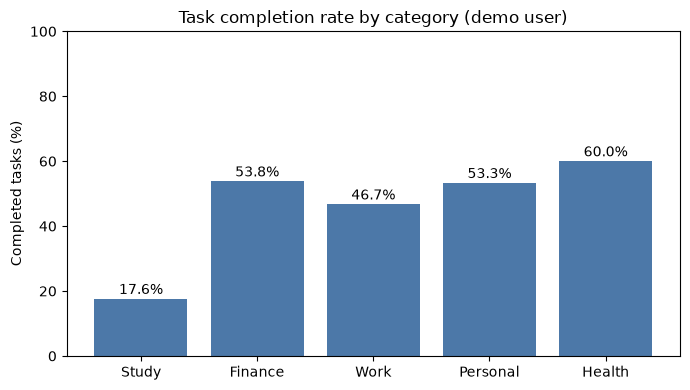

In [17]:
# 2) Completion rate by category
comp = pd.DataFrame(requests.get(BASE_URL + "/analytics/completion-by-category", headers=headers).json())
print(comp)

plt.figure(figsize=(7, 4))
bars = plt.bar(comp["category"], comp["completion_rate"], color="#4C78A8")
plt.title("Task completion rate by category (demo user)")
plt.ylabel("Completed tasks (%)")
plt.ylim(0, 100)
for b, v in zip(bars, comp["completion_rate"]):
    plt.text(b.get_x() + b.get_width()/2, v + 1.5, f"{v}%", ha="center")
plt.tight_layout()
plt.show()

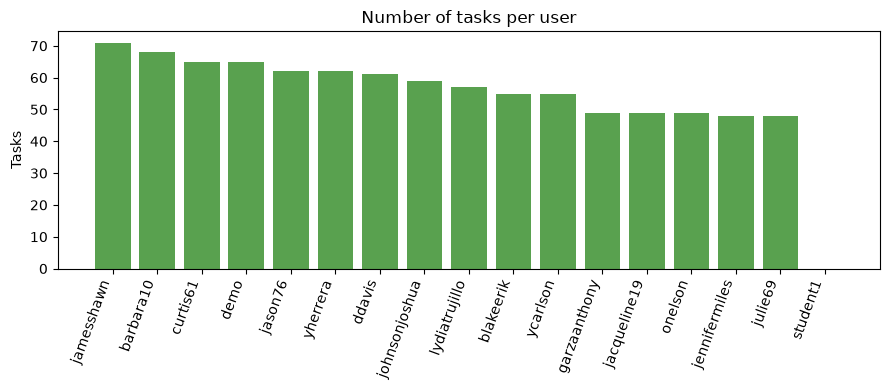

In [18]:
# 3) Tasks per user (uses a JOIN between users and tasks)
per_user = pd.DataFrame(requests.get(BASE_URL + "/analytics/tasks-per-user", headers=headers).json())

plt.figure(figsize=(9, 4))
plt.bar(per_user["username"], per_user["task_count"], color="#59A14F")
plt.title("Number of tasks per user")
plt.ylabel("Tasks")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

Tasks fetched: 65


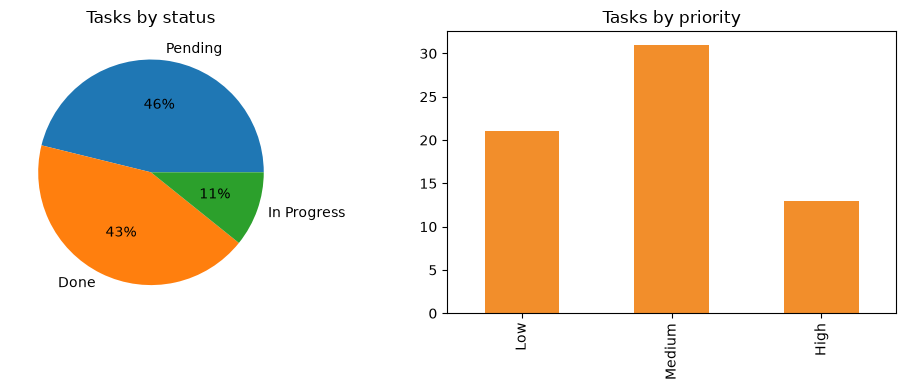

In [19]:
# 4) Status and priority split of the demo user's tasks (fetch all pages through the API)
all_tasks, page = [], 1
while True:
    data = requests.get(BASE_URL + "/tasks", headers=headers, params={"page": page, "page_size": 100}).json()
    all_tasks += data["items"]
    if page * 100 >= data["total"]:
        break
    page += 1
df = pd.DataFrame(all_tasks)
print("Tasks fetched:", len(df))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["status"].value_counts().plot.pie(ax=ax[0], autopct="%1.0f%%", ylabel="", title="Tasks by status")
df["priority"].value_counts().reindex(["Low", "Medium", "High"]).plot.bar(ax=ax[1], color="#F28E2B", title="Tasks by priority")
ax[1].set_xlabel("")
plt.tight_layout()
plt.show()

In [20]:
# stop the server when finished
server.should_exit = True
time.sleep(1)
print("Server stopped")

Server stopped


## 11. Conclusion

**What was built:** a working REST API with a MySQL database, two linked tables, secure login, full CRUD on tasks, search / filter / pagination, three analytics endpoints, seed data and automated tests, all run from this notebook.

**Concepts demonstrated:** REST API design, ORM-based database integration, one-to-many relationships with foreign keys and indexes, token-based authentication, input validation, SQL aggregation (`GROUP BY`, `JOIN`) and data visualisation.

**Limitations and future work**
- The seeded data is synthetic, not real user data.
- Only a simple title search is supported.
- A web front end (HTML or Streamlit) could be added on top of the API.
- Database migrations (Alembic) and unit tests with `pytest` could be added.

**Reference:** base project https://github.com/isaac0yen/Python-CRUD